# Faster R-CNN, RT-DETR, YOLO11s and RetinaNet: extended class-wise WBF ensemble (pipeline, tuned)

## Overview

Parent run: `pipeline-ensemble-wbf` (P5, run `dmnk1304/pipeline-ensemble-wbf`, notebook `new-notebooks/pipeline-ensemble-wbf.ipynb`): class-wise weighted boxes fusion (WBF, Solovyev et al., arXiv:1910.13302) of the saved detections of five current-protocol runs (T1, T2, T3, P3, T7). This notebook trains nothing. It reads the saved predictions of finished runs (kernel sources) and fuses them. It uses no GPU: all of it runs on the CPU, and it works in a CPU-only Kaggle session. `uv run push-notebook` attaches a T4 accelerator by default and the notebook does not use it, so `gpu_name` is recorded as "none (CPU)" when no GPU is present.

**What changes.** One thing: the member set. The five P5 members are joined by up to five more, which already exist as saved outputs (`SCOPE.md` F65). The members (the `SOURCE_KERNELS` of the Config) are:

| Label | Run | Family | Protocol | Resolution | mAP@500 | AP_small | Public LB |
|---|---|---|---|---|---|---|---|
| T1 | `draklowell/faster-rcnn-small-anchors` | two_stage | current | 1280 | 0.2312 | 0.1212 | 0.24489 |
| T2 | `dmnk1304/faster-rcnn-rpn-proposals` | two_stage | current | 1280 | 0.2290 | 0.1194 | 0.2332 |
| T3 | `dmnk1304/faster-rcnn-giou` | two_stage | current | 1280 | 0.2371 | 0.1312 | 0.22569 |
| P3 | `draklowell/pipeline-class-balance` | two_stage (pipeline) | current | 1280 | 0.2247 | 0.1163 | 0.25857 |
| T7 | `dmnk1304/yolo11s-1280-p2` | anchor_free | current | 1280 | 0.2165 | 0.1146 | not recorded |
| T11 | `draklowell/faster-rcnn-short-schedule` | two_stage | current | 1280 | 0.2287 | 0.1064 | not recorded |
| FC5 | `dmnk1304/faster-cnn-5` | two_stage | legacy | 1280 | 0.2416 | 0.0994 | 0.21972 |
| RTD | `dmnk1304/rt-detr-tuned-lr` | query | legacy | 640 | 0.2123 | 0.0889 | not recorded |
| Y3 | `dmnk1304/yolo-3-1280` | anchor_free | legacy | 1280 | 0.1930 | 0.0900 | 0.19618 |
| RN | `draklowell/retinanet` | one_stage_anchor | legacy | 1280 | 0.2055 | 0.0569 | 0.21420 |

Metrics: full val, `EXPERIMENTS.md` (legacy rows are marked there with a dagger). The recorded `mAP` of each member is compared with a fresh COCOeval of its saved val detections. The five current-protocol members read it from their `result.json`. The legacy result files are incomplete, so the four legacy `mAP` values are Config constants copied from `EXPERIMENTS.md`. A legacy member whose files are missing from the attached sources is skipped, and the notebook lists it in the member table and in `result.json` (`skipped_kernels`).

| Item | P5 (parent) | This run |
|---|---|---|
| Members | 5 current-protocol runs | up to 10 (6 current-protocol, 4 legacy) |
| Confidence type | `avg`, fixed | searched on quick-val frames: `WBF_CONFIDENCE_TYPE_GRID` |
| IoU threshold, `skip_box_thr` | 6 × 3 grid | 3 × 2 grid (forced by run time, see Cost) |
| Member weights | each of 5 members at 0.5 and 2.0 | each of up to 10 members at the values of `WBF_WEIGHT_GRID` |
| Ablation | 12 fused subsets (185 min) | none; one row per removed member on the frames outside quick-val |
| Extra analyses | `val_noise.csv`, `bus_diagnostic.csv` | not repeated |
| Headline | full val | full val and the 2,275 val frames outside quick-val |
| Session | CPU, evaluations run one after another | same |

Config constants of the change: `SOURCE_KERNELS`, `WBF_CONFIDENCE_TYPE_GRID`, `WBF_IOU_THRESHOLD_GRID`, `WBF_SKIP_BOX_THRESHOLD_GRID`. The smaller IoU and `skip_box_thr` grids are a forced side change: the run evaluates twice as many members, and the grids were reduced to stay within the CPU time budget. The values are taken from P5's search range (it tuned IoU 0.5 to 0.75 and `skip_box_thr` 0.001 to 0.05). `PARENT_RUN` names P5; `result.json` lists the member kernels under `source_kernels`.

**Why** (`SCOPE.md` findings F57, F58, F62, F65, numbers in `EXPERIMENTS.md` and `experiments/dmnk1304/pipeline-ensemble-wbf.md`):
- P5 fused five runs into full-val mAP@500 0.2747 against 0.2371 for its best member. In its ablation, the cross-family pair T3+T7 (0.2654) is above the four Faster R-CNN runs fused together (0.2608), and adding T7 to the four gives +0.0106 while the weight tuning gives +0.0033 (F58, F62). Members from other families, resolutions and anchor sets are therefore the next lever.
- Four legacy runs saved `val_predictions_*.json` and `submission.csv` (F65), so they cost no GPU time: `faster-cnn-5` (Faster R-CNN with anchors 32 to 512), `rt-detr-tuned-lr` (a transformer detector at 640 px), `yolo-3-1280` (YOLO11s without the P2 head) and `retinanet` (a dense one-stage detector). T11 is a sixth Faster R-CNN run with a 6-epoch schedule.
- Hypothesis 3 of the P5 report: with `conf_type = "avg"` a box found by one member of five keeps a fifth of its score, which may push single-member boxes below the 500-detection cut, and AR500 fell from 0.5048 to 0.4842 under the tuned weights. With ten members the factor becomes a tenth. The report suggested rerunning with `max` or `box_and_model_avg`, so both are searched here.

**Expectation.** The added families are expected to add diversity, but the legacy members are weaker than the P5 members, so their weights may stay low. The size of the effect is not predicted. A guess from `SCOPE.md`, not measured: +0.005 to +0.015 mAP@500 over P5. The decision rule of `SCOPE.md` §3.10 applies against P5: full-val mAP@500 at least 0.01 above P5 and a per-clip AP delta of the same sign on at least 5 of the 7 val clips. P5 is not a kernel source here, so the comparison uses `per_clip_ap.csv` of both runs, and the table of this notebook contains a row that re-fuses the five P5 members with P5's settings.

**Comparison with the legacy parent (legacy members).** P5 and the six current-protocol members (T1, T2, T3, P3, T7, T11) ran under the current protocol, so no protocol difference enters their comparison with this ensemble. The four legacy members ran under the older protocol (the dagger notes in `EXPERIMENTS.md`):
- `faster-cnn-5` and `retinanet`: no ignore fill (ignored areas trained as background); GT inside ignore regions not dropped; GT boxes under 1 px dropped; no cuDNN determinism; checkpoint chosen by quick-val mAP, as in the current protocol; submission boxes under 0.5 px dropped.
- `rt-detr-tuned-lr` and `yolo-3-1280`: no ignore fill; GT inside ignore regions not dropped; checkpoint = Ultralytics `best.pt` by fitness (mAP50-95) on all val frames, with no quick-val COCOeval; no `seed_everything` and no time guard; submission coordinates rounded to 1 decimal; `yolo-3-1280` does not clip its boxes to the image in its notebook (this notebook clips every member box to the image before the fusion).
- All four: result files without versions, speed protocol and other core keys; legacy output names (`val_predictions_<name>.json`, `submission.csv`).

The val numbers of the legacy members are therefore not comparable with the current-protocol ones: the Ultralytics members were selected on the frames they are evaluated on, which makes their val score optimistic. The delta of this ensemble over P5 mixes the member set with the protocol difference of the added members. Decisions use P5 and the current-protocol members as the valid comparison.

**Tuning and validity.**
- The WBF settings (confidence type, IoU threshold, `skip_box_thr`, member weights) are tuned on the 571 quick-val frames only (every 5th `val/` frame). Metrics are reported on all 2,846 val frames and on the 2,275 frames outside quick-val. The outside frames were not used by the fusion tuning. They were used to select the checkpoints of the two legacy Ultralytics members, so they are not free of selection for those members.
- Nothing is fitted on training data, and no model weights are learned. The tuned values are one confidence type, two scalars and up to ten member weights. The settings are never tuned on the full val or on test.
- The current-protocol members were trained on `train/` clips only. The legacy members were also trained on `train/` clips only (the same every-5th-frame split), so the fused val score is a hold-out score.
- Test detections are the fusion of the members' `submission.csv` files (top 500 per image), with the settings chosen on quick-val.

**Cost (estimate from the P5 timings, not measured).** P5 took 53.0 min for five member evaluations, 54.4 min for 28 tuning trials and 184.8 min for its 12-subset ablation (`SCOPE.md` F61). This run evaluates up to ten members, runs 18 trials in stage 1 and up to 20 in stage 2 with a larger member set per trial, and fuses once per removed member. Expect several hours of CPU time. `MAX_TRAIN_HOURS = 6` bounds the weight search of the tuning only. The Kaggle limit of 12 h is the hard ceiling.

**Extra outputs of this run.** Besides the standard outputs, `per_clip_ap.csv` and `size_breakdown.csv`:
- `history.csv`: the tuning trace (one row per evaluated setting, with quick-val mAP and AP50); there are no training epochs;
- `ensemble_ablation.csv`: each member alone (full val), the P5 configuration (the five P5 members with P5's settings), the final ensemble, and one row per removed member (frames outside quick-val);
- `fig_tuning_quick_val.png` and `fig_ensemble_ablation.png` (+ `.csv`).

`best.pt` and the training curves do not apply, because nothing is trained.

**Protocol**

- Train: every 5th frame (`FRAME_STEP`) of each of the 56 `train/` clips, 4,868 frames. The split is by clip; no `val/` clip is used for training.
- Validation: all 2,846 frames of the 7 `val/` clips. Quick validation after every epoch: every 5th `val/` frame (`QUICK_VAL_STEP`), 571 frames.
- Ignore regions: in training frames, every ignore box is filled with the frame's own per-channel mean before augmentation, and GT boxes fully inside an ignore box are dropped. Val and test frames are not filled; evaluation treats ignore regions as `iscrowd=1`.
- Metric: pycocotools `COCOeval` on `val/annotations_coco.json` with `maxDets = [1, 100, 500]`; headline `mAP` is AP@[.50:.95] at 500 detections per frame. Inference in fp32 with score threshold 0.001 and at most 500 detections per frame.
- Checkpoint selection: the epoch with the best quick-val mAP. Quick val is a subset of val, so the final val score is slightly optimistic.
- Budget: `EPOCHS` planned epochs (Ultralytics 30, torchvision 12) and a `MAX_TRAIN_HOURS = 6` wall-clock guard, single Tesla T4.
- Reproducibility: `SEED = 42` and deterministic settings. Runs are reproducible in setup but not guaranteed bit-exact.

**How the protocol applies to a fusion run.**
- The split, the 56 training clips and the ignore handling belong to the members' training. This notebook only checks the frame counts. It does not fill ignore regions, because it trains nothing. Evaluation uses the same `val/annotations_coco.json` with `iscrowd=1`.
- There are no epochs. The "checkpoint" is the WBF setting with the best quick-val mAP@500, and `MAX_TRAIN_HOURS` bounds the weight search. The members' detections come from fp32 inference with score threshold 0.001 and at most 500 detections per frame; the fused output is capped at 500 detections per frame as well.
- Speed: the fusion runs on the CPU. `ms_per_image` in `result.json` is the sum of the members' recorded `ms_per_image` plus the fusion time per frame (see `speed_protocol`).

**How weighted boxes fusion works**

Non-maximum suppression keeps one box of a group of overlapping boxes and drops the rest. WBF (Solovyev, Wang, Gabruseva, arXiv:1910.13302) uses all of them. The detections of all members are pooled per class (class-wise fusion, `SCOPE.md` F10) and sorted by score. Each box is compared with the fused boxes built so far: if the IoU with one of them is above `iou_thr`, it joins that cluster, and otherwise it starts a new one. A fused box is the average of the cluster's coordinates weighted by the box scores. Boxes with a score below `skip_box_thr` are dropped before the clustering.

The score of a fused box depends on `conf_type` (`ensemble-boxes` 1.0.10; the score of every box is first multiplied by its member's weight). The fused detections of a frame are sorted by score and cut at 500, and the scores are clipped to [0, 1].
- `avg`: the mean of the scores in the cluster, rescaled by `min(number of members, cluster size) / sum of all member weights`. A box that only one of ten members found keeps a tenth of its score, and a box found by all members keeps the average score.
- `max`: the largest score in the cluster, divided by the largest member weight. Agreement between members does not change the score.
- `box_and_model_avg`: the mean of the scores, rescaled by the cluster size over the summed weights of the cluster's boxes, and then by the summed weights of the distinct members present in the cluster over the sum of all member weights.

Requires: Kaggle CPU session, Internet on.

## Setup

The only install is `ensemble-boxes` (MIT licence), pinned in the `kaggle` dependency group of `pyproject.toml`; it implements WBF. torch, torchvision, pycocotools, numpy, polars and matplotlib come with the Kaggle image. Their versions are printed here and recorded in `result.json`.

In [1]:
%pip install -q ensemble-boxes==1.0.10

Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import io
import json
import platform
import random
import time
from collections.abc import Callable
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.figure import Figure

from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

Seeding helper and the version banner. Nothing in this notebook uses the GPU, so it runs in a CPU-only Kaggle session, and `gpu_name` is recorded as "none (CPU)" when no GPU is present.

In [3]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


started_at = datetime.now(UTC).isoformat(timespec="seconds")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)"
package_versions = {
    "python": platform.python_version(),
    **{
        name: version(name)
        for name in ["torch", "torchvision", "pycocotools", "numpy", "polars", "matplotlib", "ensemble-boxes"]
    },
}
print(" | ".join(f"{name} {value}" for name, value in package_versions.items()), "| GPU:", gpu_name)

python 3.13.18 | torch 2.11.0+cpu | torchvision 0.26.0+cpu | pycocotools 2.0.11 | numpy 2.1.3 | polars 1.35.2 | matplotlib 3.10.0 | ensemble-boxes 1.0.10 | GPU: none (CPU)


## Config

Deviations from the single-run notebooks, with reasons:
- `SOURCE_KERNELS` and `KERNEL_INPUT_ROOT`: the members' outputs are read from the kernel sources attached to this kernel. `MEMBER_LABELS` gives the short run labels in the same order; the first five are the P5 members. The mount path `/kaggle/input/notebooks/<owner>/<kernel>` worked in P5 (`SCOPE.md` F61). A missing file of a current-protocol member raises `FileNotFoundError`. A legacy member (a key of `LEGACY_VAL_FILE_BY_KERNEL`) whose val or test file is missing is skipped, and the skip is shown in the member table and recorded in `result.json`.
- `LEGACY_VAL_FILE_BY_KERNEL`: the legacy runs wrote `val_predictions_<name>.json`; their test file is `submission.csv` like the others. The names are those listed in the artifact tables of the reports in `experiments/`.
- `LEGACY_RECORD_BY_KERNEL`: the legacy result files lack core keys, so `mAP`, `ms_per_image`, `train_hours` and `imgsz` of the four legacy members are copied from `EXPERIMENTS.md`. The recorded `mAP` is only used to check that the attached file belongs to the expected run.
- `P5_*` constants: the settings P5 chose on quick-val (IoU 0.7, `skip_box_thr` 0.001, `avg`, weights T1 0.5, T2 0.5, T3 1.0, P3 0.5, T7 2.0). They are used only for the table row that re-fuses the five P5 members, so that P5 and this run are compared on the same frames.
- `WBF_CONFIDENCE_TYPE_GRID`, `WBF_IOU_THRESHOLD_GRID`, `WBF_SKIP_BOX_THRESHOLD_GRID`: the grid of the first tuning stage (equal weights). The library defaults are 0.55 and 0.0. The IoU grid is a subset of P5's range, and the smallest skip value equals the score threshold of the members' detections (`CONF_THRESHOLD`).
- `WBF_WEIGHT_GRID`: the second tuning stage tries each member at these weights, one member at a time, starting from the best stage-1 setting and the default weight `WBF_DEFAULT_WEIGHT`. A weight is kept only if it raises the quick-val mAP@500.
- `MEMBER_RESULT_TOLERANCE`: the largest allowed difference between a member's recorded `mAP` and the `mAP` recomputed here from its saved val detections.
- `EXPECTED_OUTSIDE_QUICK_VAL_FRAMES`: the val frames that are not quick-val frames (2,846 − 571).
- `MAX_TRAIN_HOURS = 6` bounds the tuning search; the weight search stops before the next member if the limit is passed.

In [4]:
DATA_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
OUTPUT_DIR = Path("/kaggle/working")
SCRATCH_DIR = Path("/kaggle/temp")
KERNEL_INPUT_ROOT = Path("/kaggle/input/notebooks")
SOURCE_KERNELS = (
    "draklowell/faster-rcnn-small-anchors",
    "dmnk1304/faster-rcnn-rpn-proposals",
    "dmnk1304/faster-rcnn-giou",
    "draklowell/pipeline-class-balance",
    "dmnk1304/yolo11s-1280-p2",
    "draklowell/faster-rcnn-short-schedule",
    "dmnk1304/faster-cnn-5",
    "dmnk1304/rt-detr-tuned-lr",
    "dmnk1304/yolo-3-1280",
    "draklowell/retinanet",
)
MEMBER_LABELS = ("T1", "T2", "T3", "P3", "T7", "T11", "FC5", "RTD", "Y3", "RN")
CURRENT_VAL_FILE_NAME = "val_predictions.json"
TEST_FILE_NAME = "submission.csv"
LEGACY_VAL_FILE_BY_KERNEL = {
    "dmnk1304/faster-cnn-5": "val_predictions_faster_rcnn_r50fpn_v2_1280.json",
    "dmnk1304/rt-detr-tuned-lr": "val_predictions_rtdetr_l_640_lr1e-4.json",
    "dmnk1304/yolo-3-1280": "val_predictions_yolo11s_1280.json",
    "draklowell/retinanet": "val_predictions_retinanet_r50fpn_v2_1280.json",
}
LEGACY_RECORD_BY_KERNEL: dict[str, dict[str, float]] = {
    "dmnk1304/faster-cnn-5": {"mAP": 0.2416, "ms_per_image": 198.3, "train_hours": 3.37, "imgsz": 1280},
    "dmnk1304/rt-detr-tuned-lr": {"mAP": 0.2123, "ms_per_image": 42.8, "train_hours": 3.34, "imgsz": 640},
    "dmnk1304/yolo-3-1280": {"mAP": 0.1930, "ms_per_image": 27.7, "train_hours": 2.71, "imgsz": 1280},
    "draklowell/retinanet": {"mAP": 0.2055, "ms_per_image": 113.8, "train_hours": 2.40, "imgsz": 1280},
}
P5_MEMBER_LABELS = ("T1", "T2", "T3", "P3", "T7")
P5_WEIGHTS = (0.5, 0.5, 1.0, 0.5, 2.0)
P5_IOU_THRESHOLD = 0.7
P5_SKIP_BOX_THRESHOLD = 0.001
P5_CONFIDENCE_TYPE = "avg"

Run identity, protocol constants, tuning grids, figure settings, the data-root check and the seed.

In [5]:
RUN_NAME = "pipeline-ensemble-extended"
MODEL_NAME = (
    "class-wise WBF (ensemble-boxes 1.0.10) of up to ten saved runs: Faster R-CNN R50-FPN v2, "
    "YOLO11s, RT-DETR-L and RetinaNet"
)
FAMILY = "pipeline"
VARIANT = "tuned"
PARENT_RUN = "pipeline-ensemble-wbf"
CHANGED_PARAMS: list[str] = [
    "SOURCE_KERNELS",
    "WBF_CONFIDENCE_TYPE_GRID",
    "WBF_IOU_THRESHOLD_GRID",
    "WBF_SKIP_BOX_THRESHOLD_GRID",
]

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
FRAME_STEP = 5
QUICK_VAL_STEP = 5
EXPECTED_TRAIN_CLIPS = 56
EXPECTED_TRAIN_FRAMES = 4868
EXPECTED_VAL_CLIPS = 7
EXPECTED_VAL_FRAMES = 2846
EXPECTED_QUICK_VAL_FRAMES = 571
EXPECTED_OUTSIDE_QUICK_VAL_FRAMES = 2275
EXPECTED_TEST_FRAMES = 3811
CONF_THRESHOLD = 0.001
MAX_DETECTIONS = 500
MAX_TRAIN_HOURS = 6
IGNORE_STRATEGY = "per_image_mean_fill"

WBF_CONFIDENCE_TYPE_GRID = ("avg", "max", "box_and_model_avg")
WBF_IOU_THRESHOLD_GRID = (0.6, 0.7, 0.75)
WBF_SKIP_BOX_THRESHOLD_GRID = (0.001, 0.01)
WBF_WEIGHT_GRID = (0.5, 2.0)
WBF_DEFAULT_WEIGHT = 1.0
MEMBER_RESULT_TOLERANCE = 5e-4
SPEED_PROTOCOL = (
    "sum of the members' recorded ms_per_image (each with its own speed protocol, Tesla T4, fp32; legacy and "
    "current-protocol members differ) plus perf_counter around the WBF call per frame on the CPU in one process, "
    "all val frames, member inference excluded"
)

SMALL_AREA = 32**2
MEDIUM_AREA = 96**2

FIGURE_SIZE = (12, 5)
FIGURE_DPI = 100
FIGURE_IMAGE_MAX_SIDE = 960

if not (DATA_ROOT / "test_images.csv").is_file():
    raise FileNotFoundError(f"Competition data not found under {DATA_ROOT}")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)

## Data

Frames are listed per split and identified by the key `<clip>/<frame>.jpg`. The members trained on every `FRAME_STEP`-th frame of each `train/` clip; this notebook lists the same split only to check the counts of the protocol. Validation uses every `val/` frame, and quick validation (the tuning set) every `QUICK_VAL_STEP`-th one.

In [6]:
def to_frame_key(path: str | Path) -> str:
    return "/".join(Path(path).parts[-2:])


def list_frames(split: str) -> pl.DataFrame:
    image_paths = sorted(str(path) for path in (DATA_ROOT / split / "images").rglob("*.jpg"))
    return pl.DataFrame({"path": image_paths}, schema={"path": pl.String}).with_columns(
        clip=pl.col("path").str.split("/").list.get(-2),
        frame_key=pl.col("path").str.split("/").list.slice(-2).list.join("/"),
    )


def select_every_nth_frame(frames: pl.DataFrame, step: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == 0)


def require_count(name: str, actual: int, expected: int) -> None:
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, got {actual}")


train_frames = select_every_nth_frame(list_frames("train"), FRAME_STEP)
val_frames = list_frames("val")
quick_val_frames = select_every_nth_frame(val_frames, QUICK_VAL_STEP)

require_count("train clips", train_frames["clip"].n_unique(), EXPECTED_TRAIN_CLIPS)
require_count("train frames", train_frames.height, EXPECTED_TRAIN_FRAMES)
require_count("val clips", val_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("val frames", val_frames.height, EXPECTED_VAL_FRAMES)
require_count("quick-val frames", quick_val_frames.height, EXPECTED_QUICK_VAL_FRAMES)
print(f"train {train_frames.height} | val {val_frames.height} | quick val {quick_val_frames.height} frames")

train 4868 | val 2846 | quick val 571 frames


Ground truth of the val split comes from `annotations_coco.json`; `iscrowd=1` entries and boxes under 1 px are excluded from the GT arrays used by the analyses. The COCOeval itself reads the same file, so ignore regions are handled as `iscrowd=1`. The training-side helpers (ignore boxes of training frames, mean fill) are not needed here: the members applied them when they trained, and this notebook trains nothing.

In [7]:
def load_ground_truth(split: str) -> tuple[pl.DataFrame, dict[str, np.ndarray]]:
    coco = json.loads((DATA_ROOT / split / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        "width",
        "height",
        image_id=pl.col("id"),
        frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/"),
    )
    targets = (
        pl.DataFrame(coco["annotations"])
        .filter(pl.col("iscrowd") == 0)
        .select(
            "image_id",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
        .join(images.select("image_id", "frame_key"), on="image_id")
    )
    target_columns = ["x1", "y1", "x2", "y2", "class_id"]
    targets_by_key = {key: np.zeros((0, 5), dtype=np.float32) for key in images["frame_key"]}
    for (key,), frame_targets in targets.group_by("frame_key"):
        targets_by_key[str(key)] = frame_targets.select(target_columns).to_numpy().astype(np.float32)
    return images, targets_by_key

Apply the helper to the val split, and index the val and test frames: image ids, image sizes (the fusion works on boxes normalised by the image size) and the key lists. The frames outside quick-val (2,275 frames) are the val frames that the fusion tuning never sees. The test frames come from `test_images.csv`; the competition data has no `sample_submission.csv`.

In [8]:
val_images, val_targets_by_key = load_ground_truth("val")
val_image_id_by_key = dict(val_images.select("frame_key", "image_id").iter_rows())
key_by_val_image_id = {image_id: key for key, image_id in val_image_id_by_key.items()}
val_size_by_key = {
    key: (width, height) for key, width, height in val_images.select("frame_key", "width", "height").iter_rows()
}
val_keys = val_frames["frame_key"].to_list()
quick_val_keys = quick_val_frames["frame_key"].to_list()
quick_val_image_ids = [val_image_id_by_key[key] for key in quick_val_keys]
quick_val_key_set = set(quick_val_keys)
outside_quick_val_keys = [key for key in val_keys if key not in quick_val_key_set]
outside_quick_val_image_ids = [val_image_id_by_key[key] for key in outside_quick_val_keys]
require_count("outside quick-val frames", len(outside_quick_val_keys), EXPECTED_OUTSIDE_QUICK_VAL_FRAMES)
val_clips = sorted(val_frames["clip"].unique().to_list())

test_images = pl.read_csv(DATA_ROOT / "test_images.csv").with_columns(
    frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/")
)
require_count("test frames", test_images.height, EXPECTED_TEST_FRAMES)
test_keys = test_images["frame_key"].to_list()
test_key_by_image_id = dict(test_images.select("image_id", "frame_key").iter_rows())
test_size_by_key = {
    key: (width, height) for key, width, height in test_images.select("frame_key", "width", "height").iter_rows()
}
print(
    f"val GT frames {len(val_targets_by_key)} | outside quick-val {len(outside_quick_val_keys)} "
    f"| test frames {len(test_keys)} | val clips {len(val_clips)}"
)

val GT frames 2846 | outside quick-val 2275 | test frames 3811 | val clips 7


Evaluation helpers, copied from the single-run notebooks: conversion to the COCO results format and COCOeval at `maxDets = [1, 100, 500]`. `COCO.loadRes` mutates its input, so `evaluate_coco` passes copies. `COCOeval.eval` mixes value types, so the precision array is checked explicitly before slicing. `FrameDetections` is `(boxes, scores, class_ids)` with boxes `xyxy` in original pixels, float scores and 0-based class ids.

In [9]:
type FrameDetections = tuple[np.ndarray, np.ndarray, np.ndarray]


def to_coco_results(
    detections_by_key: dict[str, FrameDetections], image_id_by_key: dict[str, int]
) -> list[dict[str, object]]:
    return [
        {
            "image_id": image_id_by_key[key],
            "category_id": int(class_id) + 1,
            "bbox": [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)],
            "score": round(score, 4),
        }
        for key, (boxes, scores, class_ids) in detections_by_key.items()
        for (x1, y1, x2, y2), score, class_id in zip(boxes.tolist(), scores.tolist(), class_ids.tolist(), strict=True)
    ]


def load_coco_ground_truth(split: str) -> COCO:
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(DATA_ROOT / split / "annotations_coco.json"))


def evaluate_coco(
    ground_truth: COCO, detections: list[dict[str, object]], image_ids: list[int] | None = None
) -> COCOeval:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes([dict(item) for item in detections]), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def read_precision_at_max_detections(evaluator: COCOeval) -> np.ndarray:
    precision = evaluator.eval["precision"]
    if not isinstance(precision, np.ndarray):
        raise RuntimeError("COCOeval has no precision array; call accumulate() first")
    return precision[:, :, :, 0, -1]


def compute_map_at_max_detections(evaluator: COCOeval) -> float:
    precision = read_precision_at_max_detections(evaluator)
    return float(np.mean(precision[precision > -1]))


val_ground_truth = load_coco_ground_truth("val")

Headline metrics and the per-class table. `stats[0]` is AP at maxDets 100; `stats[1..5]` and `stats[8]` are already at maxDets 500. Size buckets are COCO's 32² / 96² in original pixels.

In [10]:
def summarise_metrics(evaluator: COCOeval) -> dict[str, float]:
    stats = evaluator.stats
    return {
        "mAP": round(compute_map_at_max_detections(evaluator), 4),
        "mAP_maxdet100": round(float(stats[0]), 4),
        "AP50": round(float(stats[1]), 4),
        "AP75": round(float(stats[2]), 4),
        "AP_small": round(float(stats[3]), 4),
        "AP_medium": round(float(stats[4]), 4),
        "AP_large": round(float(stats[5]), 4),
        "AR500": round(float(stats[8]), 4),
    }


def average_valid_precision(precision: np.ndarray) -> float | None:
    valid_precision = precision[precision > -1]
    return round(float(valid_precision.mean()), 4) if valid_precision.size else None


def build_per_class_ap(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_precision_at_max_detections(evaluator)
    return pl.DataFrame(
        [
            {
                "class_id": class_id,
                "class_name": class_name,
                "AP": average_valid_precision(precision[:, :, class_id]),
                "AP50": average_valid_precision(precision[0, :, class_id]),
            }
            for class_id, class_name in enumerate(CLASSES)
        ],
        schema={"class_id": pl.Int64, "class_name": pl.String, "AP": pl.Float64, "AP50": pl.Float64},
    )

Per-clip AP. The val set has 7 clips, and one 4K clip is 34 % of its frames (EDA summary `EDA.md`, §5), so COCOeval also runs on each clip alone: the detections are filtered to the clip's frames and evaluated against the same ground truth. `evaluate_detections` runs the whole chain for one set of detections and returns the headline metrics, on all val frames or on a given subset of image ids.

In [11]:
def round_valid_metric(value: float) -> float | None:
    return round(float(value), 4) if value > -1 else None


def build_per_clip_ap(predictions: list[dict[str, object]]) -> pl.DataFrame:
    image_ids_by_clip = (
        val_images.with_columns(clip=pl.col("frame_key").str.split("/").list.get(0))
        .group_by("clip")
        .agg(pl.col("image_id"))
        .sort("clip")
    )
    rows = []
    for clip, image_ids in image_ids_by_clip.iter_rows():
        clip_image_ids = set(image_ids)
        clip_predictions = [item for item in predictions if item["image_id"] in clip_image_ids]
        evaluator = evaluate_coco(val_ground_truth, clip_predictions, image_ids)
        rows.append(
            {
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP50": round_valid_metric(evaluator.stats[1]),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
    return pl.DataFrame(
        rows,
        schema={
            "clip": pl.String,
            "frames": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AP_small": pl.Float64,
        },
    )


def evaluate_detections(
    detections_by_key: dict[str, FrameDetections], image_ids: list[int] | None = None
) -> dict[str, float]:
    predictions = to_coco_results(detections_by_key, val_image_id_by_key)
    return summarise_metrics(evaluate_coco(val_ground_truth, predictions, image_ids))

Independent evaluations (one WBF setting, one member, one removed member) run one after another in the main process. A forked process pool hung on Kaggle in P5 (polars is multi-threaded, and forking it can deadlock), so the evaluations are sequential, and each job prints its run time.

In [12]:
def run_jobs[Job](function: Callable[[Job], dict[str, float]], jobs: list[Job]) -> list[dict[str, float]]:
    results = []
    for index, job in enumerate(jobs, start=1):
        job_started = time.time()
        results.append(function(job))
        print(f"job {index}/{len(jobs)} | {(time.time() - job_started) / 60:.1f} min", flush=True)
    return results

Member predictions. Each source kernel must have finished and must be attached as a kernel source; its files are read from `KERNEL_INPUT_ROOT / <owner> / <kernel>`. For validation, the member's saved val file (COCO results format, at most 500 detections per frame) is turned into `(boxes, scores, class_ids)` per frame key; frames without detections get empty arrays. For test, `submission.csv` (`class score x y w h` groups, top 500 per image) is parsed the same way, and groups with a zero width or height are dropped (the legacy Ultralytics notebooks rounded to 1 decimal); every member must cover all 3,811 test frames. Boxes stay in float64, so a single member round-trips through the COCO format without change. A current-protocol member's `result.json` provides the recorded `mAP`, `ms_per_image`, `train_hours` and `imgsz`, and its `run` must equal the kernel slug. A legacy member takes them from `LEGACY_RECORD_BY_KERNEL`.

In [13]:
MEMBER_RECORD_KEYS = ("mAP", "ms_per_image", "train_hours", "imgsz")


def get_val_file_name(kernel: str) -> str:
    return LEGACY_VAL_FILE_BY_KERNEL.get(kernel, CURRENT_VAL_FILE_NAME)


def is_member_available(kernel: str) -> bool:
    return all((KERNEL_INPUT_ROOT / kernel / name).is_file() for name in (get_val_file_name(kernel), TEST_FILE_NAME))


def read_member_file(kernel: str, file_name: str) -> Path:
    path = KERNEL_INPUT_ROOT / kernel / file_name
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing: attach the finished source kernel {kernel}")
    return path


def read_member_record(kernel: str) -> dict[str, float]:
    if kernel in LEGACY_RECORD_BY_KERNEL:
        return LEGACY_RECORD_BY_KERNEL[kernel]
    result = json.loads(read_member_file(kernel, "result.json").read_text())
    if result["run"] != kernel.split("/")[1]:
        raise ValueError(f"{kernel}: result.json belongs to run {result['run']}")
    return {key: float(result[key]) for key in MEMBER_RECORD_KEYS}


def build_empty_detections() -> FrameDetections:
    return np.zeros((0, 4)), np.zeros(0), np.zeros(0, dtype=np.int64)


def load_member_val_detections(kernel: str) -> dict[str, FrameDetections]:
    predictions = (
        pl.DataFrame(
            json.loads(read_member_file(kernel, get_val_file_name(kernel)).read_text()),
            schema={"image_id": pl.Int64, "category_id": pl.Int64, "bbox": pl.List(pl.Float64), "score": pl.Float64},
        )
        .select(
            "image_id",
            "score",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") > pl.col("x1")) & (pl.col("y2") > pl.col("y1")))
    )
    detections_by_key = {key: build_empty_detections() for key in val_keys}
    for (image_id,), frame in predictions.group_by("image_id"):
        detections_by_key[key_by_val_image_id[int(image_id)]] = (
            frame.select("x1", "y1", "x2", "y2").to_numpy(),
            frame["score"].to_numpy(),
            frame["class_id"].to_numpy(),
        )
    return detections_by_key


def load_member_test_detections(kernel: str) -> dict[str, FrameDetections]:
    submission = pl.read_csv(
        read_member_file(kernel, TEST_FILE_NAME), schema={"image_id": pl.String, "PredictionString": pl.String}
    ).with_columns(pl.col("PredictionString").fill_null(""))
    detections_by_key: dict[str, FrameDetections] = {}
    for image_id, prediction_string in submission.iter_rows():
        all_groups = np.array(prediction_string.split(), dtype=np.float64).reshape(-1, 6)
        groups = all_groups[(all_groups[:, 4] > 0) & (all_groups[:, 5] > 0)]
        boxes = np.stack([groups[:, 2], groups[:, 3], groups[:, 2] + groups[:, 4], groups[:, 3] + groups[:, 5]], axis=1)
        detections_by_key[test_key_by_image_id[image_id]] = (boxes, groups[:, 1], groups[:, 0].astype(np.int64))
    require_count(f"{kernel} test frames", len(detections_by_key), EXPECTED_TEST_FRAMES)
    return detections_by_key

Load the members and show one row per source kernel. A legacy member with a missing val or test file is skipped (`status`), and all later steps use the loaded members only. `val_detections` and `test_detections` count the detections that enter the fusion. The first five labels must be the P5 members.

In [14]:
require_count("member labels", len(MEMBER_LABELS), len(SOURCE_KERNELS))
skipped_kernels = [
    kernel for kernel in SOURCE_KERNELS if kernel in LEGACY_VAL_FILE_BY_KERNEL and not is_member_available(kernel)
]
loaded_members = [
    (label, kernel)
    for label, kernel in zip(MEMBER_LABELS, SOURCE_KERNELS, strict=True)
    if kernel not in skipped_kernels
]
member_labels = tuple(label for label, _ in loaded_members)
member_kernels = tuple(kernel for _, kernel in loaded_members)
member_records = [read_member_record(kernel) for kernel in member_kernels]
val_detections_by_member = [load_member_val_detections(kernel) for kernel in member_kernels]
test_detections_by_member = [load_member_test_detections(kernel) for kernel in member_kernels]
p5_indices = tuple(member_labels.index(label) for label in P5_MEMBER_LABELS)
member_table = pl.DataFrame(
    {
        "label": list(MEMBER_LABELS),
        "kernel": list(SOURCE_KERNELS),
        "status": ["skipped: files missing" if kernel in skipped_kernels else "loaded" for kernel in SOURCE_KERNELS],
    }
).join(
    pl.DataFrame(
        {
            "label": list(member_labels),
            "recorded_mAP": [record["mAP"] for record in member_records],
            "val_detections": [sum(len(item[1]) for item in member.values()) for member in val_detections_by_member],
            "test_detections": [sum(len(item[1]) for item in member.values()) for member in test_detections_by_member],
        }
    ),
    on="label",
    how="left",
)
member_table

label,kernel,status,recorded_mAP,val_detections,test_detections
str,str,str,f64,i64,i64
"""T1""","""draklowell/faster-rcnn-small-a…","""loaded""",0.2312,971854,1385931
"""T2""","""dmnk1304/faster-rcnn-rpn-propo…","""loaded""",0.229,1422819,1898664
"""T3""","""dmnk1304/faster-rcnn-giou""","""loaded""",0.2371,1302843,1805941
"""P3""","""draklowell/pipeline-class-bala…","""loaded""",0.2247,821982,1108890
"""T7""","""dmnk1304/yolo11s-1280-p2""","""loaded""",0.2165,1056149,1527200
"""T11""","""draklowell/faster-rcnn-short-s…","""loaded""",0.2287,1060093,1351026
"""FC5""","""dmnk1304/faster-cnn-5""","""loaded""",0.2416,638003,793223
"""RTD""","""dmnk1304/rt-detr-tuned-lr""","""loaded""",0.2123,853800,1143300
"""Y3""","""dmnk1304/yolo-3-1280""","""loaded""",0.193,1022137,1458005


Member check and baseline rows. Each loaded member's saved full-val detections are evaluated here (full-val COCOeval). The recomputed `mAP` must match the member's recorded `mAP` within `MEMBER_RESULT_TOLERANCE`; otherwise the notebook raises, because the attached files would not belong to the run it expects. The rows are the single-member rows of `ensemble_ablation.csv`.

In [15]:
def evaluate_single_member(member_index: int) -> dict[str, float]:
    return evaluate_detections(val_detections_by_member[member_index])


single_rows = run_jobs(evaluate_single_member, list(range(len(member_kernels))))
for label, row, member_record in zip(member_labels, single_rows, member_records, strict=True):
    if abs(row["mAP"] - member_record["mAP"]) > MEMBER_RESULT_TOLERANCE:
        raise ValueError(f"{label}: recomputed mAP {row['mAP']} differs from recorded {member_record['mAP']}")
pl.DataFrame(
    {
        "label": list(member_labels),
        "recomputed_mAP": [row["mAP"] for row in single_rows],
        "recorded_mAP": [member_record["mAP"] for member_record in member_records],
    }
)

job 1/10 | 4.7 min
job 2/10 | 6.4 min
job 3/10 | 5.1 min
job 4/10 | 4.2 min
job 5/10 | 6.9 min
job 6/10 | 4.8 min
job 7/10 | 2.7 min
job 8/10 | 4.7 min
job 9/10 | 6.4 min
job 10/10 | 6.7 min


label,recomputed_mAP,recorded_mAP
str,f64,f64
"""T1""",0.2312,0.2312
"""T2""",0.229,0.229
"""T3""",0.2371,0.2371
"""P3""",0.2247,0.2247
"""T7""",0.2165,0.2165
"""T11""",0.2287,0.2287
"""FC5""",0.2416,0.2416
"""RTD""",0.2123,0.2123
"""Y3""",0.193,0.193


## Model

The model of this run is the fusion function, with no learned weights. `fuse_frame` normalises every member's boxes by the image size, clips them to [0, 1], calls `weighted_boxes_fusion` of `ensemble-boxes` with the setting's `conf_type`, sorts the result by score, keeps the top `MAX_DETECTIONS`, scales the boxes back to original pixels, clips them to the image and clips the scores to [0, 1]. Frames where no member has a detection give empty arrays. The library fuses per class, so detections of different classes are never merged (class-wise fusion, `SCOPE.md` F10). A `FusionSetting` is `(member weights, IoU threshold, skip_box_thr, confidence type)`; the next section tunes it.

In [16]:
type FusionSetting = tuple[tuple[float, ...], float, float, str]


def fuse_frame(
    member_detections: list[FrameDetections],
    size: tuple[int, int],
    setting: FusionSetting,
) -> FrameDetections:
    if all(len(scores) == 0 for _, scores, _ in member_detections):
        return build_empty_detections()
    weights, iou_threshold, skip_box_threshold, confidence_type = setting
    width, height = size
    scale = np.array([width, height, width, height], dtype=np.float64)
    boxes, scores, class_ids = weighted_boxes_fusion(
        [(boxes / scale).clip(0, 1) for boxes, _, _ in member_detections],
        [scores for _, scores, _ in member_detections],
        [class_ids for _, _, class_ids in member_detections],
        weights=list(weights),
        iou_thr=iou_threshold,
        skip_box_thr=skip_box_threshold,
        conf_type=confidence_type,
    )
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    return (
        (boxes[top_indices] * scale).clip(0, scale),
        scores[top_indices].clip(0.0, 1.0),
        class_ids[top_indices].astype(np.int64),
    )


def fuse_frames(
    detections_by_member: list[dict[str, FrameDetections]],
    keys: list[str],
    size_by_key: dict[str, tuple[int, int]],
    setting: FusionSetting,
) -> dict[str, FrameDetections]:
    return {
        key: fuse_frame([detections[key] for detections in detections_by_member], size_by_key[key], setting)
        for key in keys
    }


default_weights = (WBF_DEFAULT_WEIGHT,) * len(member_kernels)
print(
    f"WBF ensemble-boxes {package_versions['ensemble-boxes']} | {len(member_kernels)} members "
    f"| cap {MAX_DETECTIONS} detections per frame"
)

WBF ensemble-boxes 1.0.10 | 10 members | cap 500 detections per frame


## Training

There is no gradient training. This section tunes the fusion on the quick-val frames only (571 frames, every 5th `val/` frame): that set is the selection set of the run, as for the checkpoint selection of the members. The score of a setting is our COCOeval mAP@500 on the quick-val frames.

Two stages, each trial evaluated one after another:
1. Stage 1: every combination of `WBF_CONFIDENCE_TYPE_GRID`, `WBF_IOU_THRESHOLD_GRID` and `WBF_SKIP_BOX_THRESHOLD_GRID` with equal member weights.
2. Stage 2: starting from the best stage-1 setting, each member in turn is tried at every value of `WBF_WEIGHT_GRID` with the other weights as they are. A weight change is kept only if the quick-val mAP@500 rises strictly. One pass over the members; the loop stops early if `MAX_TRAIN_HOURS` is passed.

Ties go to the earlier setting in the grid. The trace is written to `history.csv` (columns `val_mAP` and `val_AP50` are the quick-val metrics of the setting).

In [17]:
def score_quick_val(setting: FusionSetting) -> dict[str, float]:
    detections_by_key = fuse_frames(val_detections_by_member, quick_val_keys, val_size_by_key, setting)
    evaluator = evaluate_coco(
        val_ground_truth, to_coco_results(detections_by_key, val_image_id_by_key), quick_val_image_ids
    )
    return {
        "val_mAP": round(compute_map_at_max_detections(evaluator), 4),
        "val_AP50": round(float(evaluator.stats[1]), 4),
    }


def pick_best_trial(scores: list[dict[str, float]]) -> int:
    return int(np.argmax([score["val_mAP"] for score in scores]))


history_rows: list[dict[str, object]] = []
tuning_started = time.time()


def run_trials(stage: int, settings: list[FusionSetting]) -> list[dict[str, float]]:
    scores = run_jobs(score_quick_val, settings)
    for (weights, iou_threshold, skip_box_threshold, confidence_type), score in zip(settings, scores, strict=True):
        history_rows.append(
            {
                "step": len(history_rows) + 1,
                "stage": stage,
                "confidence_type": confidence_type,
                "iou_threshold": iou_threshold,
                "skip_box_threshold": skip_box_threshold,
                "weights": " ".join(f"{weight:g}" for weight in weights),
                **score,
                "minutes": round((time.time() - tuning_started) / 60, 1),
            }
        )
    return scores

Stage 1: the confidence type, IoU threshold and `skip_box_thr` grid with equal weights.

In [18]:
stage_one_settings: list[FusionSetting] = [
    (default_weights, iou_threshold, skip_box_threshold, confidence_type)
    for confidence_type in WBF_CONFIDENCE_TYPE_GRID
    for iou_threshold in WBF_IOU_THRESHOLD_GRID
    for skip_box_threshold in WBF_SKIP_BOX_THRESHOLD_GRID
]
stage_one_scores = run_trials(1, stage_one_settings)
best_setting = stage_one_settings[pick_best_trial(stage_one_scores)]
best_quick_val_map = max(score["val_mAP"] for score in stage_one_scores)
print(
    f"stage 1: {len(stage_one_settings)} settings | best {best_setting[3]} | IoU {best_setting[1]:g} "
    f"| skip {best_setting[2]:g} | quick-val mAP {best_quick_val_map:.4f} "
    f"| {(time.time() - tuning_started) / 60:.1f} min"
)

job 1/18 | 3.7 min
job 2/18 | 2.8 min
job 3/18 | 3.6 min
job 4/18 | 2.7 min
job 5/18 | 3.7 min
job 6/18 | 2.7 min
job 7/18 | 3.8 min
job 8/18 | 2.8 min
job 9/18 | 3.7 min
job 10/18 | 2.8 min
job 11/18 | 3.7 min
job 12/18 | 2.7 min
job 13/18 | 4.0 min
job 14/18 | 2.9 min
job 15/18 | 4.0 min
job 16/18 | 2.9 min
job 17/18 | 4.0 min
job 18/18 | 2.9 min
stage 1: 18 settings | best box_and_model_avg | IoU 0.7 | skip 0.001 | quick-val mAP 0.2874 | 59.3 min


Stage 2: member weights, one member at a time, from the best stage-1 setting.

In [19]:
for member_index, label in enumerate(member_labels):
    if (time.time() - tuning_started) / 3600 > MAX_TRAIN_HOURS:
        break
    current_weights, current_iou_threshold, current_skip_box_threshold, current_confidence_type = best_setting
    candidates: list[FusionSetting] = [
        (
            current_weights[:member_index] + (weight,) + current_weights[member_index + 1 :],
            current_iou_threshold,
            current_skip_box_threshold,
            current_confidence_type,
        )
        for weight in WBF_WEIGHT_GRID
    ]
    candidate_scores = run_trials(2, candidates)
    top_index = pick_best_trial(candidate_scores)
    is_accepted = candidate_scores[top_index]["val_mAP"] > best_quick_val_map
    if is_accepted:
        best_setting = candidates[top_index]
        best_quick_val_map = candidate_scores[top_index]["val_mAP"]
    print(
        f"member {label} | best weight {WBF_WEIGHT_GRID[top_index]:g} "
        f"| quick-val mAP {candidate_scores[top_index]['val_mAP']:.4f}{' | accepted' if is_accepted else ''}",
        flush=True,
    )

tuned_weights, tuned_iou_threshold, tuned_skip_box_threshold, tuned_confidence_type = best_setting
tuning_hours = (time.time() - tuning_started) / 3600
history = pl.DataFrame(history_rows)
history.write_csv(OUTPUT_DIR / "history.csv")
print(
    f"tuning {tuning_hours:.2f} h | settings {history.height} | {tuned_confidence_type} | IoU {tuned_iou_threshold:g} "
    f"| skip {tuned_skip_box_threshold:g} | weights {list(tuned_weights)} | quick-val mAP {best_quick_val_map:.4f}"
)

job 1/2 | 4.0 min
job 2/2 | 4.1 min
member T1 | best weight 0.5 | quick-val mAP 0.2884 | accepted
job 1/2 | 4.0 min
job 2/2 | 4.1 min
member T2 | best weight 0.5 | quick-val mAP 0.2882
job 1/2 | 4.0 min
job 2/2 | 4.0 min
member T3 | best weight 2 | quick-val mAP 0.2882
job 1/2 | 4.0 min
job 2/2 | 4.0 min
member P3 | best weight 0.5 | quick-val mAP 0.2893 | accepted
job 1/2 | 4.0 min
job 2/2 | 4.1 min
member T7 | best weight 2 | quick-val mAP 0.2903 | accepted
job 1/2 | 4.1 min
job 2/2 | 4.1 min
member T11 | best weight 0.5 | quick-val mAP 0.2916 | accepted
job 1/2 | 4.1 min
job 2/2 | 4.0 min
member FC5 | best weight 2 | quick-val mAP 0.2911
job 1/2 | 4.1 min
job 2/2 | 4.1 min
member RTD | best weight 2 | quick-val mAP 0.2906
job 1/2 | 4.1 min
job 2/2 | 4.1 min
member Y3 | best weight 0.5 | quick-val mAP 0.2911
job 1/2 | 4.1 min
job 2/2 | 4.1 min
member RN | best weight 2 | quick-val mAP 0.2918 | accepted
tuning 2.34 h | settings 38 | box_and_model_avg | IoU 0.7 | skip 0.001 | weights [

Figures: every figure is saved as `fig_<name>.png` with its data as `fig_<name>.csv`.

In [20]:
def save_figure(fig: Figure, name: str, data: pl.DataFrame) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_{name}.png", dpi=FIGURE_DPI)
    data.write_csv(OUTPUT_DIR / f"fig_{name}.csv")
    plt.show()
    plt.close(fig)

Tuning figure. Left: stage 1, quick-val mAP@500 by WBF IoU threshold with one line per confidence type and `skip_box_thr` (equal weights). Right: stage 2, quick-val mAP@500 of every weight trial (tick label = weights of the members in `MEMBER_LABELS` order, skipped members left out), with the best equal-weight setting as a dashed line.

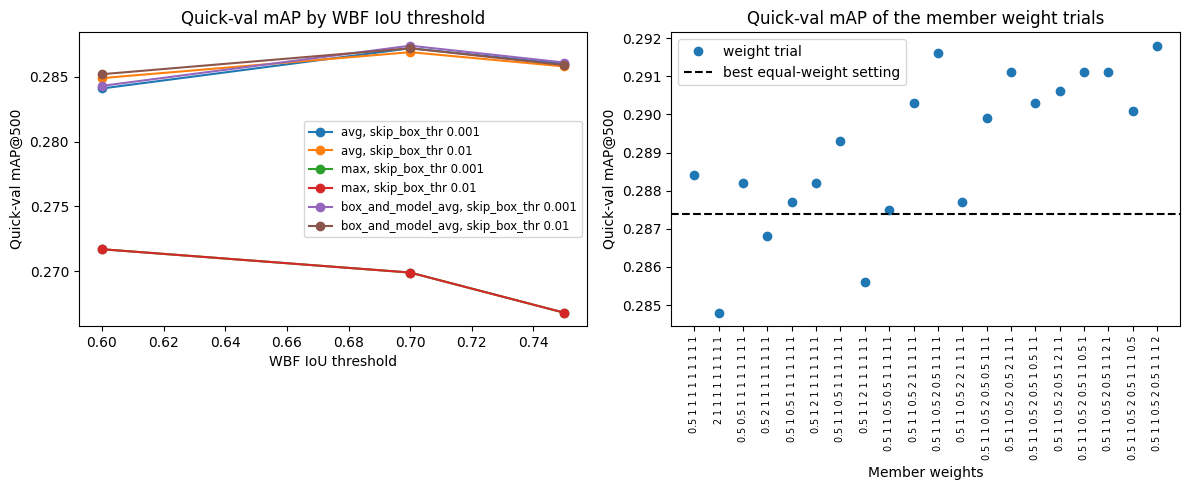

In [21]:
stage_one = history.filter(pl.col("stage") == 1)
stage_two = history.filter(pl.col("stage") == 2)
fig, (grid_ax, weight_ax) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
for confidence_type in WBF_CONFIDENCE_TYPE_GRID:
    for skip_box_threshold in WBF_SKIP_BOX_THRESHOLD_GRID:
        rows = stage_one.filter(
            (pl.col("confidence_type") == confidence_type) & (pl.col("skip_box_threshold") == skip_box_threshold)
        )
        grid_ax.plot(
            rows["iou_threshold"],
            rows["val_mAP"],
            marker="o",
            label=f"{confidence_type}, skip_box_thr {skip_box_threshold:g}",
        )
grid_ax.set_title("Quick-val mAP by WBF IoU threshold")
grid_ax.set_xlabel("WBF IoU threshold")
grid_ax.set_ylabel("Quick-val mAP@500")
grid_ax.legend(fontsize="small")
weight_ax.plot(range(stage_two.height), stage_two["val_mAP"], marker="o", linestyle="", label="weight trial")
weight_ax.axhline(stage_one["val_mAP"].max(), linestyle="--", color="black", label="best equal-weight setting")
weight_ax.set_xticks(range(stage_two.height), labels=stage_two["weights"].to_list())
weight_ax.tick_params(axis="x", labelrotation=90, labelsize="x-small")
weight_ax.set_title("Quick-val mAP of the member weight trials")
weight_ax.set_xlabel("Member weights")
weight_ax.set_ylabel("Quick-val mAP@500")
weight_ax.legend()
save_figure(fig, "tuning_quick_val", history)

## Validation

The tuned fusion is applied to all val frames. Quick val is a subset of val and was used to tune the settings (and to select the members' checkpoints), so this score is slightly optimistic. Speed protocol: the sum of the members' recorded `ms_per_image` plus `perf_counter` around the WBF call per frame (CPU, one process, all val frames, member inference excluded).

In [22]:
fusion_started = time.perf_counter()
val_detections_by_key = fuse_frames(val_detections_by_member, val_keys, val_size_by_key, best_setting)
fusion_ms_per_image = 1000 * (time.perf_counter() - fusion_started) / len(val_keys)
members_ms_per_image = sum(member_record["ms_per_image"] for member_record in member_records)
ms_per_image = members_ms_per_image + fusion_ms_per_image
val_predictions = to_coco_results(val_detections_by_key, val_image_id_by_key)
(OUTPUT_DIR / "val_predictions.json").write_text(json.dumps(val_predictions))
val_evaluator = evaluate_coco(val_ground_truth, val_predictions)
val_metrics = summarise_metrics(val_evaluator)
print(
    f"{len(val_predictions)} detections | mAP {val_metrics['mAP']:.4f} "
    f"| fusion {fusion_ms_per_image:.1f} ms/image | members {members_ms_per_image:.1f} ms/image"
)

1423000 detections | mAP 0.2904 | fusion 270.7 ms/image | members 1577.4 ms/image


Headline on the 2,275 val frames outside quick-val. The fusion tuning never saw these frames, so this number is not affected by the choice of the WBF setting. How to read this line: same detections and same COCOeval as above, restricted to `outside_quick_val_image_ids`. The checkpoints of the two legacy Ultralytics members were selected on all val frames, so the outside frames are not free of selection for those members.

In [23]:
outside_evaluator = evaluate_coco(val_ground_truth, val_predictions, outside_quick_val_image_ids)
outside_quick_val_metrics = summarise_metrics(outside_evaluator)
print(
    f"outside quick-val {len(outside_quick_val_keys)} frames | mAP {outside_quick_val_metrics['mAP']:.4f} "
    f"| AP_small {outside_quick_val_metrics['AP_small']:.4f} | AR500 {outside_quick_val_metrics['AR500']:.4f}"
)

outside quick-val 2275 frames | mAP 0.2901 | AP_small 0.1528 | AR500 0.5100


`result.json` writer: the core keys are checked before writing. Keys that do not apply to a fusion run (`imgsz`, `epochs_planned`, `epochs_run`, `best_epoch`, `batch`, `lr`) are `null`; `train_hours` is the wall-clock time of the tuning search, and the GPU hours behind the members are in `members_train_hours`. The extra keys record the member set, the skipped members, the tuned setting and the outside-quick-val headline.

In [24]:
REQUIRED_RESULT_KEYS = [
    "run",
    "notebook",
    "model",
    "family",
    "variant",
    "parent_run",
    "changed_params",
    "seed",
    "imgsz",
    "epochs_planned",
    "epochs_run",
    "best_epoch",
    "batch",
    "lr",
    "train_frames",
    "val_frames",
    "frame_step",
    "ignore_strategy",
    "mAP",
    "mAP_maxdet100",
    "AP50",
    "AP75",
    "AP_small",
    "AP_medium",
    "AP_large",
    "AR500",
    "ms_per_image",
    "speed_protocol",
    "train_hours",
    "gpu_name",
    "versions",
    "started_at",
    "finished_at",
]
FAMILIES = ["two_stage", "one_stage_anchor", "anchor_free", "query", "pipeline"]
VARIANTS = ["initial", "tuned"]


def write_result(result: dict[str, object]) -> None:
    missing_keys = [key for key in REQUIRED_RESULT_KEYS if key not in result]
    if missing_keys:
        raise ValueError(f"result.json is missing core keys: {missing_keys}")
    if result["family"] not in FAMILIES or result["variant"] not in VARIANTS:
        raise ValueError(f"Invalid family or variant: {result['family']}, {result['variant']}")
    (OUTPUT_DIR / "result.json").write_text(json.dumps(result, indent=2))

The run summary, shown as a one-row table (without the list and dict entries).

In [25]:
result: dict[str, object] = {
    "run": RUN_NAME,
    "notebook": f"new-notebooks/{RUN_NAME}.ipynb",
    "model": MODEL_NAME,
    "family": FAMILY,
    "variant": VARIANT,
    "parent_run": PARENT_RUN,
    "changed_params": CHANGED_PARAMS,
    "seed": SEED,
    "imgsz": None,
    "epochs_planned": None,
    "epochs_run": None,
    "best_epoch": None,
    "batch": None,
    "lr": None,
    "train_frames": train_frames.height,
    "val_frames": val_frames.height,
    "frame_step": FRAME_STEP,
    "ignore_strategy": IGNORE_STRATEGY,
    **val_metrics,
    "ms_per_image": round(ms_per_image, 1),
    "speed_protocol": SPEED_PROTOCOL,
    "train_hours": round(tuning_hours, 2),
    "gpu_name": gpu_name,
    "versions": package_versions,
    "started_at": started_at,
    "finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "source_kernels": list(member_kernels),
    "skipped_kernels": skipped_kernels,
    "member_labels": list(member_labels),
    "member_imgsz": [int(member_record["imgsz"]) for member_record in member_records],
    "members_ms_per_image": round(members_ms_per_image, 1),
    "fusion_ms_per_image": round(fusion_ms_per_image, 1),
    "members_train_hours": round(sum(member_record["train_hours"] for member_record in member_records), 2),
    "wbf_confidence_type": tuned_confidence_type,
    "wbf_iou_threshold": tuned_iou_threshold,
    "wbf_skip_box_threshold": tuned_skip_box_threshold,
    "wbf_member_weights": list(tuned_weights),
    "quick_val_mAP_tuned": best_quick_val_map,
    "outside_quick_val_frames": len(outside_quick_val_keys),
    "mAP_outside_quick_val": outside_quick_val_metrics["mAP"],
    "AP_small_outside_quick_val": outside_quick_val_metrics["AP_small"],
}
write_result(result)
pl.DataFrame([{key: value for key, value in result.items() if not isinstance(value, list | dict)}])

run,notebook,model,family,variant,parent_run,seed,imgsz,epochs_planned,epochs_run,best_epoch,batch,lr,train_frames,val_frames,frame_step,ignore_strategy,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,speed_protocol,train_hours,gpu_name,started_at,finished_at,members_ms_per_image,fusion_ms_per_image,members_train_hours,wbf_confidence_type,wbf_iou_threshold,wbf_skip_box_threshold,quick_val_mAP_tuned,outside_quick_val_frames,mAP_outside_quick_val,AP_small_outside_quick_val
str,str,str,str,str,str,i64,null,null,null,null,null,null,i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str,f64,f64,f64,str,f64,f64,f64,i64,f64,f64
"""pipeline-ensemble-extended""","""new-notebooks/pipeline-ensembl…","""class-wise WBF (ensemble-boxes…","""pipeline""","""tuned""","""pipeline-ensemble-wbf""",42,null,null,null,null,null,null,4868,2846,5,"""per_image_mean_fill""",0.2904,0.2894,0.541,0.2737,0.1521,0.2663,0.4789,0.511,1848.1,"""sum of the members' recorded m…",2.34,"""none (CPU)""","""2026-11-04T22:31:18+00:00""","""2026-11-05T02:13:57+00:00""",1577.4,270.7,32.1,"""box_and_model_avg""",0.7,0.001,0.2918,2275,0.2901,0.1528


Per-class AP and AP50 on all val frames. How to read this table: one row per class, AP is AP@[.50:.95] at 500 detections per frame, empty when the class has no GT in val.

In [26]:
per_class_ap = build_per_class_ap(val_evaluator)
per_class_ap.write_csv(OUTPUT_DIR / "per_class_ap.csv")
per_class_ap

class_id,class_name,AP,AP50
i64,str,f64,f64
0,"""person""",0.3173,0.7206
1,"""bicycle""",0.2967,0.624
2,"""car""",0.4432,0.6819
3,"""van""",0.3047,0.5139
4,"""truck""",0.3856,0.614
5,"""tricycle""",0.3155,0.6235
6,"""bus""",0.1061,0.1373
7,"""motor""",0.1541,0.4126


Per-clip AP of the fused detections (see the description above). How to read this table: one row per val clip; `AP` is AP@[.50:.95] at 500 detections per frame (the headline definition), `AP50` is AP at IoU 0.5, `AP_small` is AP on objects under 32² px, empty when the clip has no GT of that size. Written to `per_clip_ap.csv`.

In [27]:
per_clip_ap = build_per_clip_ap(val_predictions)
per_clip_ap.write_csv(OUTPUT_DIR / "per_clip_ap.csv")
per_clip_ap

clip,frames,AP,AP50,AP_small
str,i64,f64,f64,f64
"""uav0000086_00000_v""",464,0.3053,0.6764,0.2722
"""uav0000117_02622_v""",349,0.3266,0.6029,0.0406
"""uav0000137_00458_v""",233,0.3678,0.7477,0.0067
"""uav0000182_00000_v""",363,0.2414,0.5101,0.1827
"""uav0000268_05773_v""",978,0.168,0.2726,0.012
"""uav0000305_00000_v""",184,0.3846,0.5369,0.0416
"""uav0000339_00001_v""",275,0.3197,0.5497,0.0952


AP and recall by object size on all val frames, taken from the full-val evaluator. Buckets are COCO's, in original pixels: small < 32², medium < 96², large otherwise. How to read this table: `objects` counts the non-crowd val GT boxes in the bucket (the `all` row is the total, so rows overlap). `AP` and `AP50` are precision-based at 500 detections per frame. `AR500` is the recall averaged over IoU .50:.95 and `recall50` is the recall at IoU 0.5, both at 500 detections per frame. Written to `size_breakdown.csv`.

In [28]:
def read_eval_array(evaluator: COCOeval, name: str) -> np.ndarray:
    values = evaluator.eval[name]
    if not isinstance(values, np.ndarray):
        raise RuntimeError(f"COCOeval has no {name} array; call accumulate() first")
    return values


def build_size_breakdown(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_eval_array(evaluator, "precision")
    recall = read_eval_array(evaluator, "recall")
    areas = np.concatenate(
        [(targets[:, 2] - targets[:, 0]) * (targets[:, 3] - targets[:, 1]) for targets in val_targets_by_key.values()]
    )
    object_counts = [
        len(areas),
        int((areas < SMALL_AREA).sum()),
        int(((areas >= SMALL_AREA) & (areas < MEDIUM_AREA)).sum()),
        int((areas >= MEDIUM_AREA).sum()),
    ]
    return pl.DataFrame(
        [
            {
                "size": size_name,
                "objects": object_count,
                "AP": average_valid_precision(precision[:, :, :, area_index, -1]),
                "AP50": average_valid_precision(precision[0, :, :, area_index, -1]),
                "AR500": average_valid_precision(recall[:, :, area_index, -1]),
                "recall50": average_valid_precision(recall[0, :, area_index, -1]),
            }
            for area_index, (size_name, object_count) in enumerate(
                zip(["all", "small", "medium", "large"], object_counts, strict=True)
            )
        ],
        schema={
            "size": pl.String,
            "objects": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AR500": pl.Float64,
            "recall50": pl.Float64,
        },
    )


size_breakdown = build_size_breakdown(val_evaluator)
size_breakdown.write_csv(OUTPUT_DIR / "size_breakdown.csv")
size_breakdown

size,objects,AP,AP50,AR500,recall50
str,i64,f64,f64,f64,f64
"""all""",114132,0.2904,0.541,0.511,0.834
"""small""",21910,0.1521,0.3934,0.3239,0.721
"""medium""",79357,0.2663,0.5263,0.4823,0.8238
"""large""",12865,0.4789,0.7468,0.6845,0.9599


## Ensemble ablation

The question: what does each member give alone, what does the P5 configuration give on the same frames, and what changes when one member is removed from the final ensemble? Rows:
- each loaded member alone (its saved detections, no fusion), on all val frames;
- the P5 configuration: the five P5 members fused with P5's settings (`P5_*` constants), on all val frames and on the frames outside quick-val;
- the final ensemble (tuned setting), on all val frames and on the frames outside quick-val;
- one row `without <label>` per member: the final ensemble with that member removed, the other members keeping their tuned weights, fused and evaluated on the 2,275 frames outside quick-val only (one fusion per removed member; the full-val columns are empty).

How to read this table: one row per configuration. `config` names it; `n_members` is the number of fused members. `*_full` columns are on all 2,846 val frames and `*_outside` columns on the 2,275 frames outside quick-val. `mAP` is AP@[.50:.95] at 500 detections per frame, `AP_small` is AP on objects under 32² px and `AR500` is the recall at 500 detections. `mAP_outside_delta_to_final` is the `without <label>` row minus the final ensemble row on the outside frames. The tuned settings were chosen on quick-val frames only, so the rows that fuse members are not tuned on the outside frames; the single-member rows are slightly optimistic for the Ultralytics legacy members (see Overview). Written to `ensemble_ablation.csv`.

In [29]:
p5_setting: FusionSetting = (P5_WEIGHTS, P5_IOU_THRESHOLD, P5_SKIP_BOX_THRESHOLD, P5_CONFIDENCE_TYPE)
p5_detections_by_key = fuse_frames(
    [val_detections_by_member[index] for index in p5_indices], val_keys, val_size_by_key, p5_setting
)
p5_full_metrics = evaluate_detections(p5_detections_by_key)
p5_outside_metrics = evaluate_detections(p5_detections_by_key, outside_quick_val_image_ids)
print(
    f"P5 configuration | full mAP {p5_full_metrics['mAP']:.4f} | outside quick-val mAP {p5_outside_metrics['mAP']:.4f}"
)

P5 configuration | full mAP 0.2747 | outside quick-val mAP 0.2749


In [30]:
def evaluate_without_member(removed_index: int) -> dict[str, float]:
    kept_indices = [index for index in range(len(member_kernels)) if index != removed_index]
    kept_setting: FusionSetting = (
        tuple(tuned_weights[index] for index in kept_indices),
        tuned_iou_threshold,
        tuned_skip_box_threshold,
        tuned_confidence_type,
    )
    detections_by_key = fuse_frames(
        [val_detections_by_member[index] for index in kept_indices],
        outside_quick_val_keys,
        val_size_by_key,
        kept_setting,
    )
    return evaluate_detections(detections_by_key, outside_quick_val_image_ids)


without_member_rows = run_jobs(evaluate_without_member, list(range(len(member_kernels))))
print(f"leave-one-member-out: {len(without_member_rows)} fusions on {len(outside_quick_val_keys)} frames")

job 1/10 | 15.5 min
job 2/10 | 15.0 min
job 3/10 | 15.2 min
job 4/10 | 15.5 min
job 5/10 | 15.3 min
job 6/10 | 15.3 min
job 7/10 | 15.9 min
job 8/10 | 15.5 min
job 9/10 | 15.2 min
job 10/10 | 14.8 min
leave-one-member-out: 10 fusions on 2275 frames


In [31]:
def build_ablation_row(
    config: str, n_members: int, full: dict[str, float] | None, outside: dict[str, float] | None
) -> dict[str, object]:
    return {
        "config": config,
        "n_members": n_members,
        "mAP_full": full["mAP"] if full else None,
        "AP50_full": full["AP50"] if full else None,
        "AP_small_full": full["AP_small"] if full else None,
        "AR500_full": full["AR500"] if full else None,
        "mAP_outside": outside["mAP"] if outside else None,
        "AP_small_outside": outside["AP_small"] if outside else None,
        "AR500_outside": outside["AR500"] if outside else None,
    }


ablation = pl.DataFrame(
    [
        *[build_ablation_row(label, 1, row, None) for label, row in zip(member_labels, single_rows, strict=True)],
        build_ablation_row(
            "+".join(P5_MEMBER_LABELS) + " (P5 settings)", len(p5_indices), p5_full_metrics, p5_outside_metrics
        ),
        build_ablation_row(
            "+".join(member_labels) + " (tuned)", len(member_labels), val_metrics, outside_quick_val_metrics
        ),
        *[
            build_ablation_row(f"without {label}", len(member_labels) - 1, None, row)
            for label, row in zip(member_labels, without_member_rows, strict=True)
        ],
    ],
    infer_schema_length=None,
).with_columns(
    mAP_outside_delta_to_final=pl.when(pl.col("config").str.starts_with("without ")).then(
        pl.col("mAP_outside") - outside_quick_val_metrics["mAP"]
    )
)
ablation.write_csv(OUTPUT_DIR / "ensemble_ablation.csv")
ablation

config,n_members,mAP_full,AP50_full,AP_small_full,AR500_full,mAP_outside,AP_small_outside,AR500_outside,mAP_outside_delta_to_final
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""T1""",1,0.2312,0.4797,0.1212,0.4555,null,null,null,null
"""T2""",1,0.229,0.4789,0.1194,0.4719,null,null,null,null
"""T3""",1,0.2371,0.4896,0.1312,0.4802,null,null,null,null
"""P3""",1,0.2247,0.4613,0.1163,0.4437,null,null,null,null
"""T7""",1,0.2165,0.4288,0.1146,0.3639,null,null,null,null
…,…,…,…,…,…,…,…,…,…
"""without T11""",9,null,null,null,null,0.29,0.1515,0.5099,-0.0001
"""without FC5""",9,null,null,null,null,0.2881,0.1516,0.5088,-0.002
"""without RTD""",9,null,null,null,null,0.2862,0.1523,0.5068,-0.0039


Ablation figure: mAP@500 on the frames outside quick-val for the P5 configuration, the final ensemble and every leave-one-member-out row.

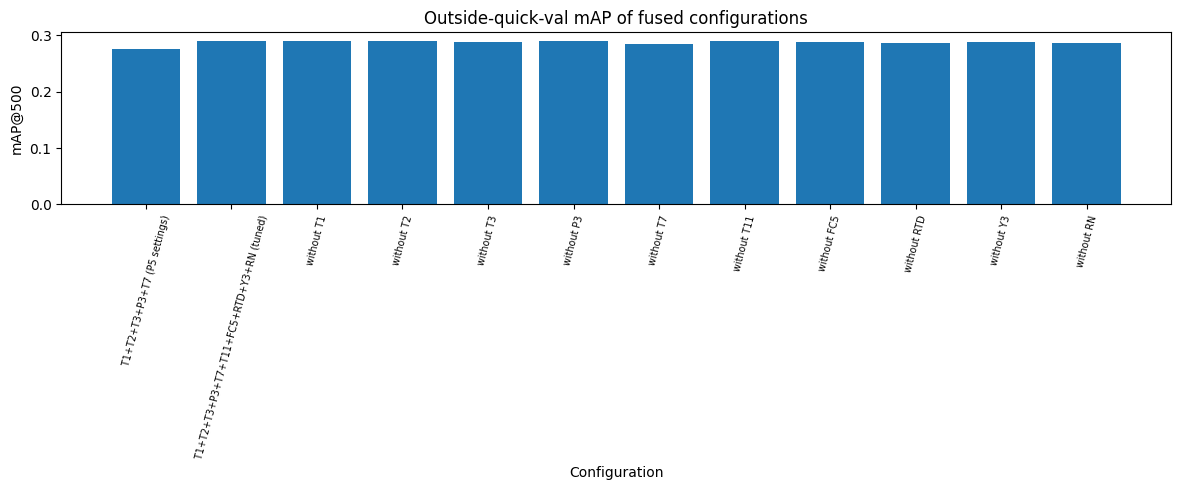

In [32]:
outside_rows = ablation.filter(pl.col("mAP_outside").is_not_null())
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.bar(range(outside_rows.height), outside_rows["mAP_outside"])
ax.set_xticks(range(outside_rows.height), labels=outside_rows["config"].to_list())
ax.tick_params(axis="x", labelrotation=75, labelsize="x-small")
ax.set_title("Outside-quick-val mAP of fused configurations")
ax.set_xlabel("Configuration")
ax.set_ylabel("mAP@500")
save_figure(fig, "ensemble_ablation", outside_rows.select("config", "n_members", "mAP_outside", "AP_small_outside"))

## Submission

Fuse the members' test detections (their `submission.csv` files) with the tuned setting and write `submission.csv`: one row per `test_images.csv` row in that order, 0-based class ids, top-left `x y w h` in original pixels, top 500 by score, empty string for frames without detections.

In [33]:
def format_prediction_string(boxes: np.ndarray, scores: np.ndarray, class_ids: np.ndarray) -> str:
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    groups = []
    for (x1, y1, x2, y2), score, class_id in zip(
        boxes[top_indices].tolist(), scores[top_indices].tolist(), class_ids[top_indices].tolist(), strict=True
    ):
        width = round(x2 - x1, 2)
        height = round(y2 - y1, 2)
        if width > 0 and height > 0:
            groups.append(f"{int(class_id)} {score:.4f} {x1:.2f} {y1:.2f} {width:.2f} {height:.2f}")
    return " ".join(groups)


test_detections_by_key = fuse_frames(test_detections_by_member, test_keys, test_size_by_key, best_setting)
prediction_by_image_id = {
    image_id: format_prediction_string(*test_detections_by_key[key])
    for image_id, key in test_images.select("image_id", "frame_key").iter_rows()
}
submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(prediction_by_image_id, default="", return_dtype=pl.String)
)
submission.write_csv(OUTPUT_DIR / "submission.csv")
print(f"submission.csv: {submission.height} rows, {(submission['PredictionString'] == '').sum()} empty")

submission.csv: 3811 rows, 0 empty


Format checks on the file as written to disk, against `test_images.csv` and the fixed columns `image_id,PredictionString` (the competition data has no `sample_submission.csv`). The results go to `submission_check.json`, and the notebook raises if any check fails.

In [34]:
SUBMISSION_COLUMNS = ["image_id", "PredictionString"]
SUBMISSION_FIELDS = ["class_id", "score", "x", "y", "w", "h"]


def check_submission(submission: pl.DataFrame, test_images: pl.DataFrame) -> dict[str, bool]:
    groups = (
        submission.join(test_images.select("image_id", "width", "height"), on="image_id", how="left")
        .filter(pl.col("PredictionString") != "")
        .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
    )
    boxes = groups.select(
        "width",
        "height",
        *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(SUBMISSION_FIELDS)],
    ).explode(SUBMISSION_FIELDS)
    return {
        "columns_match_submission_format": submission.columns == SUBMISSION_COLUMNS,
        "image_ids_match_test_images_order": submission["image_id"].equals(test_images["image_id"]),
        "image_ids_unique": bool(submission["image_id"].is_unique().all()),
        "values_multiple_of_six": bool(groups.select((pl.col("values").list.len() % 6 == 0).all()).item()),
        "at_most_max_detections_per_image": bool(
            groups.select((pl.col("values").list.len() <= 6 * MAX_DETECTIONS).all()).item()
        ),
        "class_ids_are_valid_integers": bool(
            boxes.select(
                (
                    pl.col("class_id").is_between(0, len(CLASSES) - 1)
                    & (pl.col("class_id") == pl.col("class_id").floor())
                ).all()
            ).item()
        ),
        "scores_in_unit_interval": bool(boxes["score"].is_between(0, 1).all()),
        "sizes_positive": bool(boxes.select(((pl.col("w") > 0) & (pl.col("h") > 0)).all()).item()),
        "boxes_inside_image": bool(
            boxes.select(
                (
                    (pl.col("x") >= -1)
                    & (pl.col("y") >= -1)
                    & (pl.col("x") + pl.col("w") <= pl.col("width") + 1)
                    & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)
                ).all()
            ).item()
        ),
    }


submission_on_disk = pl.read_csv(
    OUTPUT_DIR / "submission.csv", schema={"image_id": pl.String, "PredictionString": pl.String}
).with_columns(pl.col("PredictionString").fill_null(""))
submission_check = check_submission(submission_on_disk, test_images)
(OUTPUT_DIR / "submission_check.json").write_text(json.dumps(submission_check, indent=2))
failed_checks = [name for name, is_passed in submission_check.items() if not is_passed]
if failed_checks:
    raise ValueError(f"Submission checks failed: {failed_checks}")
submission_check

{'columns_match_submission_format': True,
 'image_ids_match_test_images_order': True,
 'image_ids_unique': True,
 'values_multiple_of_six': True,
 'at_most_max_detections_per_image': True,
 'class_ids_are_valid_integers': True,
 'scores_in_unit_interval': True,
 'sizes_positive': True,
 'boxes_inside_image': True}

## References

- Solovyev, Wang, Gabruseva. Weighted boxes fusion: ensembling boxes from different object detection models. arXiv:1910.13302 (WBF, class-wise fusion, confidence rescaling).
- `ensemble-boxes` 1.0.10 (`weighted_boxes_fusion`, the `conf_type` options `avg`, `max`, `box_and_model_avg`), MIT licence: https://github.com/ZFTurbo/Weighted-Boxes-Fusion
- Ren, He, Girshick, Sun. Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks. arXiv:1506.01497 (members T1, T2, T3, P3, T11, FC5).
- Lin, Goyal, Girshick, He, Dollar. Focal Loss for Dense Object Detection (RetinaNet). arXiv:1708.02002 (member RN).
- Zhao et al. DETRs Beat YOLOs on Real-time Object Detection (RT-DETR). arXiv:2304.08069 (member RTD).
- Ultralytics YOLO11 and RT-DETR (members T7, Y3, RTD, trained in their own kernels; not imported here), AGPL-3.0: https://github.com/ultralytics/ultralytics
- Lin et al. Microsoft COCO: Common Objects in Context (metric definitions). arXiv:1405.0312.
- Zhu et al. Detection and Tracking Meet Drones Challenge (VisDrone, ignored regions). arXiv:2001.06303.
- pycocotools (COCOeval), BSD-2-Clause: https://github.com/cocodataset/cocoapi
- Source runs (kernel sources): T1 `faster-rcnn-small-anchors`, T2 `faster-rcnn-rpn-proposals`, T3 `faster-rcnn-giou`, P3 `pipeline-class-balance`, T7 `yolo11s-1280-p2`, T11 `faster-rcnn-short-schedule`, and the legacy runs `faster-cnn-5`, `rt-detr-tuned-lr`, `yolo-3-1280`, `retinanet`; their reports are in `experiments/` and `EXPERIMENTS.md`. Only their saved output files are read; no legacy notebook code is used.
- Parent run P5 `pipeline-ensemble-wbf` (report `experiments/dmnk1304/pipeline-ensemble-wbf.md`, hypothesis 3 on the `avg` score rescaling): the protocol code, the fusion function, the sequential evaluation and the tuning loop are copied from `new-notebooks/pipeline-ensemble-wbf.ipynb` and its pulled CPU version `notebooks/dmnk1304/pipeline-ensemble-wbf.ipynb`.
- EDA notebook `notebooks/eda.ipynb` and its summary `EDA.md` (§5: the 4K val clip and the test resolutions).
- Planning document `SCOPE.md` (§3 principles, §3.10 decision rule, findings F10, F57, F58, F61, F62, F65) as the source of the motivation numbers in the Overview.